# Tome 8, Appendix I: Lattices and sphere packings (Python companion)

Exercises first, solutions at the end. We run Gauss's reduction, write primes as sums of two and four squares with Minkowski's lattices, build $E_8$ and count its 240 shortest vectors, compare packing densities in dimensions 2 to 8, and draw the Coxeter-plane picture of $E_8$. We use `numpy`, `itertools` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math, random
import numpy as np
import matplotlib.pyplot as plt
random.seed(9); rng = np.random.default_rng(9)

## Exercises

**P9.1 (★) Gauss reduction.** Implement Gauss's algorithm (Exercise 9.4), apply it to random bases of random plane lattices, and check Theorem 9.8: the first vector is a shortest vector (compare with a brute-force search) and $\lambda_1^2\le\frac2{\sqrt3}\det\Lambda$. Which lattices come closest to equality?

**P9.2 (★) Two squares by a lattice.** For every prime $p\equiv1\pmod 4$ below $1000$, find $m$ with $m^2\equiv-1$, reduce the lattice of Theorem 9.5, and read off $p=a^2+b^2$ from the shortest vector.

**P9.3 (★★) Four squares.** Do the same with the lattice of Exercise 9.5 in $\mathbb Z^4$, using a brute-force search for a short vector (or the LLL algorithm, if you know it).

**P9.4 (★) $E_8$ by hand.** Generate all vectors of $E_8$ of norm $2$ and $4$ (Theorem 9.10). Check that there are $240$ and $2160$, that inner products of minimal vectors lie in $\{-2,-1,0,1,2\}$ (Exercise 9.11), and count how many minimal vectors make each inner product with a fixed one.

**P9.5 (★★) Densities.** Tabulate the packing densities of $\mathbb Z^n$, $D_n$ and $D_n^+=D_n\cup(D_n+h)$ for $n=2,\dots,10$ (Exercise 9.8), and plot them against $n$ on a log scale.

**P9.6 (★★) The Coxeter plane.** Reproduce Figure 9.4: take the eight simple roots of $E_8$, multiply the eight reflections to get a Coxeter element $w$, find the eigenvalue $e^{2\pi i/30}$, and project the 240 roots onto the corresponding real plane. Draw the edges between roots with inner product $1$.

## Solutions

### P9.1
**How to find it.** The brute force enumerates small integer combinations of the random basis *before* scrambling; the theorem says that the first reduced vector wins.

In [2]:
def gauss_reduce(u, v):
    u, v = np.array(u, float), np.array(v, float)
    while True:
        if u @ u > v @ v: u, v = v, u
        mu = (u @ v) / (u @ u)
        if abs(mu) <= 0.5: return u, v
        v = v - round(mu) * u

worst = []
for trial in range(2000):
    B = rng.normal(size=(2, 2))
    U = np.array([[1, 0], [0, 1]])
    for _ in range(6):                                   # scramble the basis by random unimodular moves
        k = rng.integers(-3, 4); U = U @ (np.array([[1, k], [0, 1]]) if rng.random() < .5 else np.array([[1, 0], [k, 1]]))
    b1, b2 = (B @ U).T
    u, v = gauss_reduce(b1, b2)
    c1, c2 = B.T                                           # the unscrambled basis: short vectors have small coefficients in it
    brute = min(np.linalg.norm(a * c1 + b * c2) for a in range(-40, 41) for b in range(-40, 41) if (a, b) != (0, 0)) if trial < 200 else None
    if brute is not None: assert abs(brute - np.linalg.norm(u)) < 1e-9 * max(1, brute)
    det = abs(np.linalg.det(np.array([u, v])))
    worst.append(((u @ u) / det, np.degrees(np.arccos(abs(u @ v) / np.linalg.norm(u) / np.linalg.norm(v))), np.linalg.norm(v) / np.linalg.norm(u)))
worst.sort(reverse=True)
print('bound 2/sqrt3 = %.5f' % (2 / math.sqrt(3)))
for q, ang, ratio in worst[:4]: print('lambda1^2/det = %.5f   angle = %.1f deg   |b2|/|b1| = %.3f' % (q, ang, ratio))

bound 2/sqrt3 = 1.15470
lambda1^2/det = 1.13387   angle = 61.8 deg   |b2|/|b1| = 1.000
lambda1^2/det = 1.12814   angle = 62.1 deg   |b2|/|b1| = 1.003
lambda1^2/det = 1.12370   angle = 62.5 deg   |b2|/|b1| = 1.004
lambda1^2/det = 1.12136   angle = 61.2 deg   |b2|/|b1| = 1.017


The brute force agrees with the reduced basis every time, the ratio never exceeds $\frac2{\sqrt3}$, and the lattices that come closest have $|b_2|\approx|b_1|$ and an angle close to $60^\circ$: nearly hexagonal.

### P9.2
**How to find it.** $m$ is $g^{(p-1)/4}$ for a non-residue $g$; the reduced basis of $(1,m),(0,p)$ has first vector of squared length $p$.

In [3]:
def sqrt_minus_one(p):
    for g in range(2, p):
        if pow(g, (p - 1) // 2, p) == p - 1: return pow(g, (p - 1) // 4, p)
def is_prime(n): return n > 1 and all(n % d for d in range(2, math.isqrt(n) + 1))
res = {}
for p in range(5, 1000):
    if is_prime(p) and p % 4 == 1:
        m = sqrt_minus_one(p); assert (m * m + 1) % p == 0
        u, v = gauss_reduce((1, m), (0, p))
        a, b = int(round(abs(u[0]))), int(round(abs(u[1])))
        assert a * a + b * b == p
        res[p] = (a, b)
print(len(res), 'primes, all written as a^2 + b^2; the first few:', list(res.items())[:8])

80 primes, all written as a^2 + b^2; the first few: [(5, (1, 2)), (13, (2, 3)), (17, (1, 4)), (29, (2, 5)), (37, (1, 6)), (41, (4, 5)), (53, (2, 7)), (61, (6, 5))]


### P9.3
**How to find it.** A basis of the four-dimensional lattice is $(1,0,a,b)$, $(0,1,b,-a)$, $(0,0,p,0)$, $(0,0,0,p)$. Searching integer combinations with small coefficients of a *reduced* basis finds a vector of norm $p$; here we use a tiny LLL implementation, the $n$-dimensional cousin of Gauss's algorithm.

In [4]:
def lll(B, delta=0.75):
    B = [np.array(b, float) for b in B]; n = len(B)
    def gs(B):
        Bs, mu = [], np.zeros((n, n))
        for i in range(n):
            v = B[i].copy()
            for j in range(i):
                mu[i, j] = B[i] @ Bs[j] / (Bs[j] @ Bs[j]); v -= mu[i, j] * Bs[j]
            Bs.append(v)
        return Bs, mu
    k = 1
    while k < n:
        for j in range(k - 1, -1, -1):
            Bs, mu = gs(B)
            q = round(mu[k, j])
            if q: B[k] = B[k] - q * B[j]
        Bs, mu = gs(B)
        if Bs[k] @ Bs[k] >= (delta - mu[k, k - 1] ** 2) * (Bs[k - 1] @ Bs[k - 1]): k += 1
        else: B[k], B[k - 1] = B[k - 1], B[k]; k = max(k - 1, 1)
    return B

def four_squares(p):
    a, b = next((a, b) for a in range(p) for b in range(p) if (a * a + b * b + 1) % p == 0)
    B = lll([(1, 0, a, b), (0, 1, b, -a), (0, 0, p, 0), (0, 0, 0, p)])
    for c in itertools.product(range(-2, 3), repeat=4):
        x = sum(ci * bi for ci, bi in zip(c, B))
        if 0 < x @ x < 2 * p: return tuple(int(round(t)) for t in x)
out = {p: four_squares(p) for p in [3, 7, 31, 101, 997, 10007]}
for p, x in out.items(): print(p, x, sum(t * t for t in x))

3 (-1, 0, -1, -1) 3
7 (1, 2, 1, -1) 7
31 (1, 2, -1, 5) 31
101 (-1, 0, 0, -10) 101
997 (0, 6, -31, 0) 997
10007 (25, -63, 63, -38) 10007


### P9.4
**How to find it.** A vector of $E_8$ of norm at most $4$ has integer coordinates in $\{-2,\dots,2\}$ or half-integer coordinates in $\{\pm\frac12,\pm\frac32\}$; enumerate both families and keep those in $E_8$.

In [5]:
def in_E8(x):
    x2 = 2 * np.array(x)
    if np.all(x2 % 2 == 0): return int(sum(x)) % 2 == 0
    if np.all(x2 % 2 != 0): return int(round(sum(np.array(x) - 0.5))) % 2 == 0
    return False
shell = {2: [], 4: []}
for vals in (range(-2, 3), (-1.5, -0.5, 0.5, 1.5)):
    for x in itertools.product(vals, repeat=8):
        n2 = sum(t * t for t in x)
        if n2 in shell and in_E8(x): shell[n2].append(np.array(x, float))
print({k: len(v) for k, v in shell.items()})
R = np.array(shell[2]); G = R @ R.T
print('inner products of minimal vectors:', sorted(set(np.round(G.ravel()).astype(int))))
print('with a fixed root:', {k: int(np.sum(np.round(G[0]) == k)) for k in (-2, -1, 0, 1, 2)})

{2: 240, 4: 2160}
inner products of minimal vectors: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2)]
with a fixed root: {-2: 1, -1: 56, 0: 126, 1: 56, 2: 1}


$240$ and $2160$ vectors; a fixed root $r$ has inner product $2$ with itself, $1$ with $56$ roots, $0$ with $126$, $-1$ with $56$ and $-2$ with $-r$: $1+56+126+56+1=240$.

### P9.5
**How to find it.** $\Delta=V_n\lambda_1^n/(2^n\det)$ with $V_n=\pi^{n/2}/\Gamma(\frac n2+1)$. For $D_n^+$ (even $n$): $\det=1$ and $\lambda_1^2=\min(2,\frac n4)$.

 n   Z^n      D_n      D_n^+
 2  0.7854   nan   nan
 3  0.5236   0.7405   nan
 4  0.3084   0.6169   0.3084
 5  0.1645   0.4653   nan
 6  0.0807   0.3230   0.2725
 7  0.0369   0.2088   nan
 8  0.0159   0.1268   0.2537
 9  0.0064   0.0729   nan
10  0.0025   0.0398   0.0797


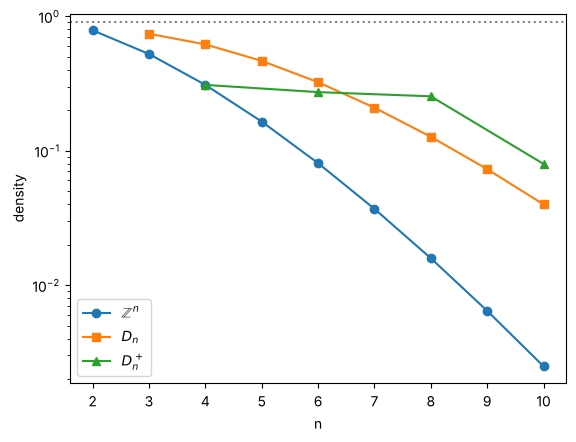

In [6]:
V = lambda n: math.pi ** (n / 2) / math.gamma(n / 2 + 1)
dens = lambda n, lam2, det: V(n) * lam2 ** (n / 2) / (2 ** n * det)
ns = range(2, 11)
rows = [(n, dens(n, 1, 1), dens(n, 2, 2) if n >= 3 else float('nan'), dens(n, min(2, n / 4), 1) if n % 2 == 0 and n >= 4 else float('nan')) for n in ns]
print(' n   Z^n      D_n      D_n^+')
for r in rows: print('%2d  %.4f   %.4f   %.4f' % r)
plt.semilogy([r[0] for r in rows], [r[1] for r in rows], 'o-', label='$\\mathbb{Z}^n$')
plt.semilogy([r[0] for r in rows], [r[2] for r in rows], 's-', label='$D_n$')
plt.semilogy([r[0] for r in rows if r[0] % 2 == 0 and r[0] >= 4], [r[3] for r in rows if r[0] % 2 == 0 and r[0] >= 4], '^-', label='$D_n^+$')
plt.axhline(math.pi / math.sqrt(12), ls=':', c='gray'); plt.xlabel('n'); plt.ylabel('density'); plt.legend(); plt.show()

$D_8^+=E_8$ with $\frac{\pi^4}{384}\approx0.2537$. Densities fall exponentially with $n$: in high dimension even the best packings fill a tiny fraction of space.

### P9.6
**How to find it.** For simple roots $\alpha$ of norm $2$ the reflection is $s_\alpha(x)=x-(\alpha\cdot x)\alpha$. The real and imaginary parts of the eigenvector of $w$ for $e^{2\pi i/30}$ span the Coxeter plane.

det of the Gram matrix of the simple roots: 1.0
eigenvalue: (0.978148+0.207912j)   w^30 = I: True   w^15 = I: False


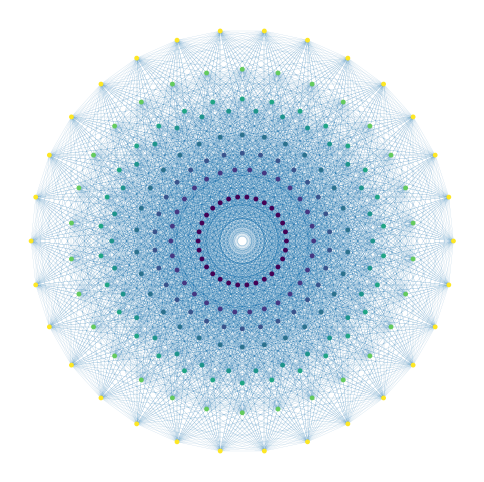

radii of the rings: [np.float64(0.2382), np.float64(0.3855), np.float64(0.4739), np.float64(0.5729), np.float64(0.7043), np.float64(0.7667), np.float64(0.927), np.float64(1.1396)]


In [7]:
simple = np.array([[1, -1, 0, 0, 0, 0, 0, 0], [0, 1, -1, 0, 0, 0, 0, 0], [0, 0, 1, -1, 0, 0, 0, 0], [0, 0, 0, 1, -1, 0, 0, 0],
                   [0, 0, 0, 0, 1, -1, 0, 0], [0, 0, 0, 0, 0, 1, 1, 0], [-.5] * 8, [0, 0, 0, 0, 0, 1, -1, 0]], float)
print('det of the Gram matrix of the simple roots:', round(np.linalg.det(simple @ simple.T), 6))
W = np.eye(8)
for a in simple: W = W @ (np.eye(8) - np.outer(a, a))
ev, Vec = np.linalg.eig(W)
k = np.argmin(abs(ev - np.exp(2j * math.pi / 30))); print('eigenvalue:', np.round(ev[k], 6), '  w^30 = I:', np.allclose(np.linalg.matrix_power(W, 30), np.eye(8)), '  w^15 = I:', np.allclose(np.linalg.matrix_power(W, 15), np.eye(8)))
u, w = Vec[:, k].real, Vec[:, k].imag
u /= np.linalg.norm(u); w -= (w @ u) * u; w /= np.linalg.norm(w)
xy = R @ np.column_stack([u, w])
fig, ax = plt.subplots(figsize=(6, 6))
for i, j in zip(*np.where(np.triu(np.round(G) == 1))):
    ax.plot(*xy[[i, j]].T, color='C0', lw=0.1, alpha=0.5)
ax.scatter(*xy.T, s=6, c=np.round(np.hypot(*xy.T), 3), cmap='viridis', zorder=3); ax.set_aspect('equal'); ax.axis('off'); plt.show()
print('radii of the rings:', sorted(set(np.round(np.hypot(*xy.T), 4))))

Eight rings of thirty points, and the $6720$ edges weave the famous rose. The number $30$ is the *Coxeter number* of $E_8$, and $240=8\times30$ is no accident: for every root system, the number of roots is the rank times the Coxeter number.